# Assignment 3 - Numerical Methods
### Moksha Kumar (DTP)

**Instructions**
* It is OK to discuss among peers, but it is **not** OK to copy each other's work or each other's functions. 
* The entire work should be done on an ipython notebook. Use markdown cells for typing your answers and code cells to define functions and their run results. 
* You should name the notebook as **your_full_name_HW3_solution.ipynb**. Use, `commit` frequently and `push` the changes to github. TAs will look at the commits and history of the notebook. DO NOT just `commit` and `push` the final version only. 
* When happy with your work and definitely before the deadline, upload the notebook into the assignment submission section of the class moodle. 
* In addition to the PDF of the HW, I have also uploaded the notebook for you to take a look at markdown formatting in case you are not sure how to do it. It is OK to download the notebook I have posted and edit it to insert your solutions. 
* Write your codes paying attention to modularity, generality, and readability. 
* How nice the plots look will carry points. 
* If you use LLM, do not copy-paste. Learn from the LLM solution. Make sure you understand it. Check if there is a simpler solution for the question. Once happy with your understanding, write it on your own without looking at the LLM solution. 

# Question 1 [2+2+2+4+4+5+2+4+2+2+4+4+5+5 marks]

In the fixed-point iteration algorithm to find roots of the equation $f(x)=0$, with a root at $x^*$, we created a modified function $g(x)=x$ and solved for the fixed points. 

1. Write an implimentation for fixed point iteration. It is OK to consult class notes, but write it on your own.
1. Consider the function $f(x)=(x-1)(x-2)$. Write a function that returns this function for any $x$. 
1. Write a function the returns the analytic derivative of this function for any $x$. 
1. Use the most obvious conversion, $g_1(x)=f(x)+x$. Write a function that returns $g_1(x)$. Show that the roots for $f(x)=0$ and $g_1(x)=x$ are the same using an appropriate figure. 
1. Use the fixedploint iteration method on $g_1(x)$ to find the roots using suitable starting points.  
1. Is it possible to find both roots with the fixed point iteration of $g_1(x)$. Explain what you find with a suitable figure clearly showing $f(x)$, $g_1(x)$, $g_1'(x)$, $x$, location of the roots, and the convergence region. 
1. In class, we found that when it converges, convergence is linear for fixed point iteration. This is because, $\left| x^{(k)} - x^* \right| = \left| x^{(k-1)} - x^* \right| \left| g'(x^{(k-1)}) \right|$. Based on this equation, we find that as $g'(x^{(k-1)})\rightarrow 0$, $\left| x^{(k)} - x^* \right| \rightarrow 0$. Does it mean that if $g'(x^{(k-1)})=0$, you are guaranteed to converge to the true root within one iteration? Explain. 
1. If $g'(x^{(k-1)})=0$, show that convergence is quadratic. 
1. Show that it is always possible to define $g_2(x) \equiv x - \dfrac{f(x)}{f'(x)}$ such that if $f(x)=0$, $g_2(x)=x$.
1. Show that for $g_2(x)$ convergence is quadratic. 
1. Analytically find $g_2(x)$ for $f(x)$ given above. Write a function that returns $g_2(x)$. 
1. Using the fixed iteration method on $g_2(x)$ and suitable starting points find the roots. 
1. Is it possible to find both roots with fixed point iteration of $g_2(x)$? Explain what you find with a suitable figure clearly showing $f(x)$, $g_2(x)$, $g_2'(x)$, $x$, location of the roots, and the convergence region. 
1. Choose a suitable starting point that can find a root both for $g_1(x)$ and $g_2(x)$. Is there a difference in the number of iterations required to find the root (with a fixed level of tolerance $\epsilon<10^{-8}$) in either case? Explain the behaviour in light of the analytic expectation considered above. 

In [112]:
# Part1, Part2, #Part3

def f(x):
    return (x-1)*(x-2)

def derivf(x):
    return 2*x-3

def g1(x):
    return (x-1)*(x-2) + x

def derivg1(x):
    return 2*x-2

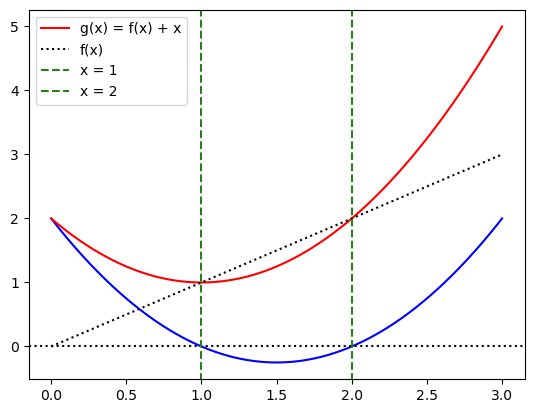

In [113]:
import numpy as np
import matplotlib.pyplot as plt

xs = np.linspace(0,3,1000)
fxs = [f(x) for x in xs]
g1xs = [g1(x) for x in xs]

plt.plot(xs, fxs, color='blue', ls='solid')
plt.axhline(0, 0, 3, ls='dotted', color='k')

plt.plot(xs, g1xs, color="red", ls='solid', label='g(x) = f(x) + x')
plt.plot(xs,xs,color='k', ls='dotted', label='f(x)')

plt.axvline(1, -2, 5, color="#2A7E19", ls='dashed', label='x = 1')
plt.axvline(2, -2, 5, color="#2A7E19", ls='dashed', label='x = 2')
plt.legend(loc="best")
#plt.axvspan(1, 2, alpha=0.2, color='blue')
plt.show()

In [114]:
#Part 5

#fixed point iteration
def fixedpoint(g, xold, kmax=200, tol=1.e-8):
    for k in range(1, kmax):
        xnew = g(xold)
        xdiff = xnew-xold
        if np.abs(xdiff/(1+xnew))<tol:
            break
        xold = xnew
    else:
        xnew = None
    return xnew

In [115]:
for xold in (0.5, 0.8, 1.2, 2.0, 2.6, 3.0):    #Checking the convergence at various points near x=1 and x=2.
    x = fixedpoint(g1, xold)
    print (xold, x)

0.5 1.0
0.8 1.0
1.2 1.0
2.0 2.0
2.6 None
3.0 None


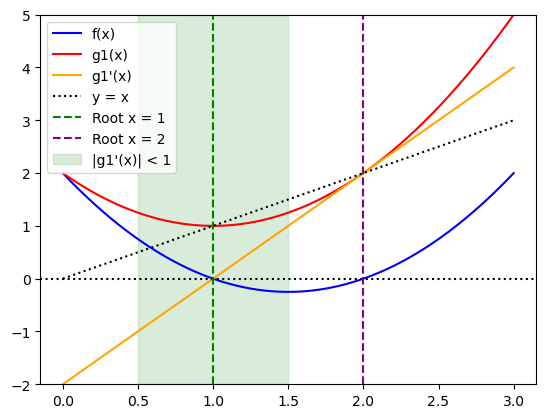

In [117]:
xs = np.linspace(0, 3, 1000)

fxs = [f(x) for x in xs]
g1xs = [g1(x) for x in xs]
dg1xs = [derivg1(x) for x in xs]

plt.plot(xs, fxs, color='blue', label='f(x)')
plt.plot(xs, g1xs, color='red', label='g1(x)')
plt.plot(xs, dg1xs, color='orange', label="g1'(x)")
plt.plot(xs, xs, color='k', ls='dotted', label='y = x')

plt.axhline(0, color='k', ls='dotted')
plt.axvline(1, color='green', ls='dashed', label='Root x = 1')
plt.axvline(2, color='purple', ls='dashed', label='Root x = 2')

plt.axvspan(0.5, 1.5, alpha=0.15, color='green',
            label="|g1'(x)| < 1")

plt.ylim(-2, 5)
plt.legend(loc='best')
plt.show()

The local convergence condition demands |g'(x*)|<1
Since g(x) = 2*x-3, therefore the region marked is between 0.5 and 1.5.
This is the local convergence condition. Not the entire basin of convergence. Infact as we can see from the results from the previous parts, the value of initial guess beyond x=1.5 also gives convergence at x=1. Further, we also note that convergence of the root x=2 only happens when the intiial guess is x=2. This is because x=2 is outside the domain (0.5,1.5)

##### Part 7

No, a zero derivative at the iterate itself does not by itself gurantee that it is the root. g'(xk-1) may be zero at some other point as well which may not be the root. 
So, the naive looking equation does not really make it converge in one step. However if our choice of the fixed point turns out to be the root itself, then certainly g'(xk-1) gurantees the convergence. But this is often quite rare start.

##### Part 8

The iteration error is ek = xk - x*, where xk = g(xk-1)
Taylor expansion around the fixed point x* gives

ek = g'(x*) ek-1 + g"(x*)/2 (ek-1)^2 + O(ek-1)^3

When sufficiently close to the root, g'(x*) vanishes.

So ek ~ g"(x*)/2 (ek-1)^2

In our case g' = 2x-2, g"=2
So ek ~ (ek-1)^2

This is clearly quadratic convergence!

##### Part 9

g2(x) = x - f(x)/f'(x).
Clearly when f(x*) = 0 and f'(x*) != 0 then g2(x*) = x
Thus, every simple root of \(f\) is a fixed point of \(g_2\). This is the Newton iteration map.

In out case g2(x) = x - (x^2 - 3x + 2)/(2x - 3) = (x^2 - 2)/(2x - 3) such that x != 3/2

##### Part 10

g2'(x) = 1 - {f'(x)^2 - f"(x)*f(x)}/f'(x)^2
g2'(x) = f"(x)*f(x)/f'(x)^2

If x* is a simple root then g2'(x*)=0. Then using Part 8 as a corollary, it must converge quadratically.

For the exact form of the convergence, we Taylor expand the function f(x) about x*: -
f(x-x*) = f'(x*)e + f"(x*)/2 e^2 + O(e^3)
enew = abs[f"(x*)/2f'(x*)]*abs[e^2]
This is clearly quadratic convergence.

In [118]:
#Part 11

def g2(x):
    return x-f(x)/derivf(x)

def derivg2(x):
    return 2*f(x)/(derivf(x)**2)

In [119]:
#Part 12

for xold in (0.5, 0.8, 1.2, 1.8, 2.2, 2.5, 3.0): #We note that we cannot include x=1.5 in this dataset
    x = fixedpoint(g2, xold)
    print(xold, x)

0.5 1.0
0.8 1.0
1.2 1.0
1.8 2.0
2.2 2.0
2.5 2.0000000000000004
3.0 2.0


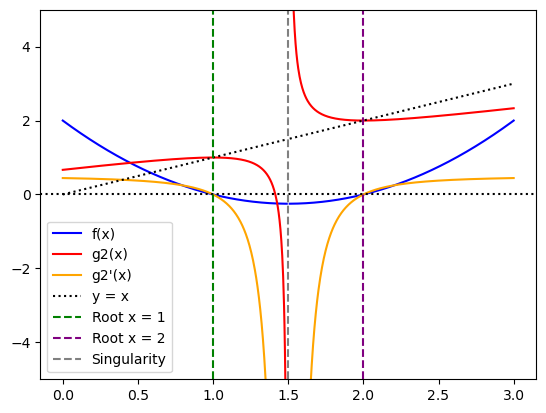

In [120]:
#Part 13

xs1 = np.linspace(0, 1.49, 500)
xs2 = np.linspace(1.51, 3, 500)

plt.plot(xs1, [f(x) for x in xs1], color='blue', label='f(x)')
plt.plot(xs2, [f(x) for x in xs2], color='blue')
plt.plot(xs1, [g2(x) for x in xs1], color='red', label='g2(x)')
plt.plot(xs2, [g2(x) for x in xs2], color='red')
plt.plot(xs1, [derivg2(x) for x in xs1], color='orange', label="g2'(x)")
plt.plot(xs2, [derivg2(x) for x in xs2], color='orange')

plt.plot(xs1, xs1, color='k', ls='dotted', label='y = x')
plt.plot(xs2, xs2, color='k', ls='dotted')

plt.axhline(0, color='k', ls='dotted')
plt.axvline(1, color='green', ls='dashed', label='Root x = 1')
plt.axvline(2, color='purple', ls='dashed', label='Root x = 2')
plt.axvline(1.5, color='gray', ls='dashed', label='Singularity')

plt.ylim(-5, 5)
plt.legend(loc='best')
plt.show()

Both x=1 and x=2 are attracting fixed points of g2(x) because g2(1)=g2(2)=0.

Unlike g1(x), the Newton map can converge to either root, depending on the starting point. In the starting points tested above, values below 1.5 converge to 1, while values above 1.5 converge to 2. The singularity at 1.5 separates these two regions for this example.

In [122]:
#Part 14

def countiterations(g, xold, kmax=200, tol=1.e-8):
    for k in range(1, kmax):
        xnew = g(xold)
        xdiff = xnew-xold
        if np.abs(xdiff/(1+xnew))<tol:
            return xnew, k
        xold = xnew
    return None, kmax-1

x1, k1 = countiterations(g1, 1.4)
x2, k2 = countiterations(g2, 1.4)

print("g1:", x1," The no. of iterations is/are: -", k1)
print("g2:", x2," The no. of iterations is/are: -", k2)

g1: 1.0  The no. of iterations is/are: - 6
g2: 1.0  The no. of iterations is/are: - 7


In my case, there is a differnce between the no. of iterations in each case. This is true because even ifboth the methods are quadratically convergent, the functional forms are different and may converge at slightly different rates.

# Question 2 [2+2+2+(3+2)+5+4+4+4+4 marks]

Consider the function $f(x) = (x-1)(x-1)(x-2)$.
1. Write a python function that evaluates $f(x)$ for any $x$. 
1. Analytically find $f'(x)$. Write a python function that evaluates the analytic derivative $f'(x)$ for any $x$. 
1. Analytically find $w(x) = f(x)/f'(x)$. Write a python function that evaluates $w(x) = f(x)/f'(x)$ for any $x$. 
1. Plot $f(x)$ and $w(x)$ as a function of $x$ using appropriate limits to show that- 
    1. $w(x)$ has the exact same roots as $f(x)$. 
    1. The multiroot at $x=1$ for $f(x)$ converts to a simple root for $w(x)$. 
1. In addition to the roots at $x=1,\ 2$, $w(x)$ appears to also cross $0$ at around $x=5/3$. Does it mean that $w(x)$ acquired an extra root compared to $f(x)$? Explain using concepts of limits and discontinuities. 
1. Write an implimentation of Newton's method to find solutions for a function. Use analytic derivative. Also use suitable domain ranges and adjust guesses as appropriate. **Note:** In class we used $\left| (x^{(k)}-x^{(k-1)})/x^{(k)} \right|<\epsilon$ for convergence. To avoid potential catestrophic cancellation, modify the tolerance condition to $\left| (x^{(k)}-x^{(k-1)})/(1+x^{(k)}) \right|<\epsilon$. 
1. Using suitable initial guesses, find all solutions of $f(x)$. 
1. Using suitable initial guesses, find all solution of $w(x)$. 
1. How does the convergence compare for the root at $x=1$ in the case of $f(x)$ and $w(x)$? 

In [124]:
#Part 1, Part 2, Part 3

import numpy as np
import matplotlib.pyplot as plt

def f(x):
    return (x-1)*(x-1)*(x-2)

def fprime(x):
    return (3*x**2 - 8*x +5)

def fbyfprime(x):
    return f(x)/fprime(x)

#We must notice that by lebniz rule of differenciation, f prime factors out
# (x-1) single time. so x=1 is a simple root of fbyfprime because one of the
# factor out of two in the numerator gets cancelled.

[]

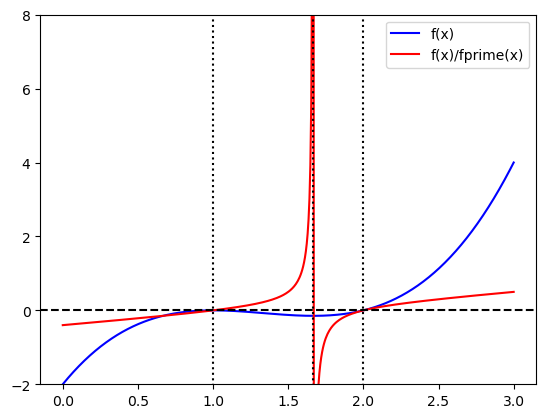

In [125]:
#Part 4

xs = np.linspace(0,3,500)
fs= [f(x) for x in xs]
fprimes = [fprime(x) for x in xs]
fbyfprimes = [fbyfprime(x) for x in xs]

plt.ylim(-2, 8)
plt.plot(xs, fs, color='blue', ls='solid', label='f(x)')
plt.plot(xs, fbyfprimes, color='red', ls='solid', label='f(x)/fprime(x)')
plt.axhline(0,0,3, color='k', ls='dashed')
plt.axvline(1,-2,8, color='k', ls='dotted')
plt.axvline(5/3,-2,8, color='k', ls='dotted')
plt.axvline(2,-2,8, color='k', ls='dotted')
plt.legend(loc='best')
plt.plot()

##### Part 5

The function w(x) = f(x)/f'(x) does not have a root at 5/3.
But our plot does have a crossing near x=5/3. This can by understood as follows: -
w(x) = (x-1)(x-1)(x-2) / (2(x-1)(x-2)+(x-1)^2) = (x-1)(x-2)/(3x-5).
So x=5/3 is actually a simple pole, not a zero.

What happens is just that python simply joins the plus infinity at (5/3)- and minus infinity at (5/3)+ and looks like a crossing. The crossing isn't the actual graph of w(x), it is just how python plots graphs by joining the data points.

In [126]:
# Part 6 : Newton Raphson method

def newton_raphson(f, fprime, x0, kmax=200, tol=1e-8):
    xiter=[x0]
    count = 0
    for k in range(1,kmax):
        count += 1
        #this loop takes care of the derivative term lurking in the denominator of Newton Rhapson equation.
        if fprime(x0) == 0:
            print("f'(x) is getting null at k =", k, " Try some other x0.")
            print("Loop is broken but we might have reached the solution:", x0)
            print("To confirm that this is indeed the correct solution, try a couple more initial guesses.")
            break
            
        #this term is the main equation of Newton Rhapson equation including the tolerance condition.
        x1 = x0 - f(x0)/fprime(x0)
        if np.abs((x1-x0)/(x1+1)) < tol:
            
            print("algo completed in", count, " steps, and the root is: ", x1)
            break
        
        x0=x1
        xiter.append(x0)
    return(x1)

In [127]:
#Part 7
print("The solution set for f(x) is the following: -\n")
initial_guesses = [-5.4, -3.4, 2.3, 6, 19, 26, 36]
for i in initial_guesses:
    root = newton_raphson(f, fprime, i, kmax=200, tol=1e-8)

The solution set for f(x) is the following: -

algo completed in 31  steps, and the root is:  0.9999999853292811
algo completed in 30  steps, and the root is:  0.9999999839901638
algo completed in 6  steps, and the root is:  2.0
algo completed in 10  steps, and the root is:  2.0
algo completed in 13  steps, and the root is:  2.0
algo completed in 14  steps, and the root is:  2.0
algo completed in 15  steps, and the root is:  2.0


In [128]:
# Part 8

def w(x):
    return (x-1)*(x-2)/(3*x-5)

def wprime(x):
    return (3*x**2 - 10*x + 9)/(3*x-5)**2

In [10]:
print("The solution set for w(x) is the following: -\n")
initial_guesses = [-5.4, -3.4, 1.8, 2.3, 3.2, 5, 26, 36]
for i in initial_guesses:
    root = newton_raphson(w, wprime, i, kmax=200, tol=1e-8)

The solution set for w(x) is the following: -

algo completed in 6  steps, and the root is:  1.0
algo completed in 6  steps, and the root is:  1.0
algo completed in 6  steps, and the root is:  2.0
algo completed in 6  steps, and the root is:  2.0
algo completed in 9  steps, and the root is:  1.0
algo completed in 7  steps, and the root is:  1.0
algo completed in 6  steps, and the root is:  1.0
algo completed in 6  steps, and the root is:  1.0


##### Part 9
The solution converges much faster for w(x) as compared to f(x) for a gereral test point. This is because: -
For f(x)=(x-1)^2(x-2), the root at x=1 has multiplicity two. Newton's method therefore converges linearly.
For w(x)=(x-1)(x-2)/(3x-5), the extended function has a simple root at x=1. Newton's method therefore converges quadratically.

# Question 3 [2+2+4+6+3+10+6+6+6 marks]

Consider the function $f(x) = x^3 - 2.5x^2 - 2.25x + 5.625$. 
1. Write a function that evaluates $f(x)$ for any $x$.
1. Find the analytic expression of $f'(x)$. Write a function that evaluates $f'(x)$ for any $x$. 
1. Plot $f(x)$ as a function of $x$. How many roots are there? 
1. Use all integers between $-5$ and $5$ (both inclusive) as initial guesses to find a root of $f(x)$ using the Newton's method function written as part of Question 2. Use tolerance of $\epsilon=10^{-16}$. What are the roots? 
1. Arrange the roots in decreasing order of how many times you found each root. Can you explain this based on the shape of $f'(x)$ at and near the initial guesses?
1. You likely found that one of the roots can only be found if the initial guess is within a narrow range in $x$ and as a result, this root is very hard to find. This is indeed a real problem in root finding in any non-bracketing methods. Depending on the shape of the function, some roots are found again and again, while the other roots remain elusive. This can lead to frustration and significant wasted computation. Moreover, unlike in this example, you often a-priori do not know how many roots are expected. As a result, you may completely miss the elusive roots and worngly interpret the function. Here we will work towards fixing this problem. Write a function that starts from an initial guess and runs Newton's method repeatedly until all roots are found. Every time a root is found, you use a modified function which is dependent on the function in the previous root finding attempt and the new-found root in the following way. Let's say first you found the root $x=x^*_0$ using $f(x)$ and $f'(x)$. Then you use a modified function $f_1(x)=\dfrac{f(x)}{(x-x^*_0)}$ and $f'_1(x)$ to look for the next root $x=x^*_1$. Once found, you use a modified function $f_2(x)=\dfrac{f_1(x)}{(x-x^*_1)}$ and $f'_2(x)$ to look for the next root. You continue until you find all roots. This function should not assume which roots will be found earlier than the others. 
1. Consider initial guesses $-5, 1, 5$. Use the modified Newton's method for each of these initial guesses. Do you find all roots from each of the initial guess? 
1. Plot $f(x)$, $f_1(x)$ and $f_2(x)$ for the initial guess $5$ which clearly shows that each modified function drops the root that is already found. 
1. Essentially, in the $k$th attempt, you are using $f_k(x)=\dfrac{f_{k-1}(x)}{(x-x^*_{k-1})}$ and $f'_k(x)$. Analytically, can you explain how this algorithm works?

**Note:** You can use either analytical derivative evaluation or a finite difference derivative evaluation. Whatever if easier to impliment for you. 

In [129]:
# Part 1, Part 2, Part 3

def f_new(x):
    return x**3 - 2.5*x**2 - 2.25*x + 5.625

def f_newprime(x):
    return 3*x**2 - 5*x -2.25

It is clear from the above picture that the function has 3 roots.


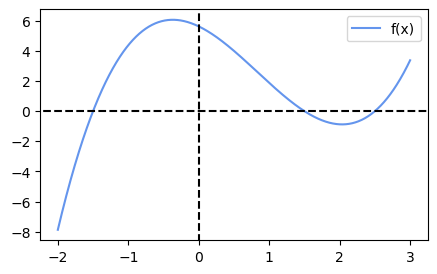

In [130]:
xs = np.linspace(-2,3,1000)
f_news = [f_new(x) for x in xs]
f_newprimes = [f_newprime(x) for x in xs]

plt.figure(figsize=(5,3))
plt.plot(xs, f_news, color='cornflowerblue', ls='solid', label='f(x)')
plt.axhline(0, -2, 3, color='k', ls='dashed')
plt.axvline(0, -8, 7, color='k', ls='dashed')
plt.legend(loc='best')
plt.plot()

print("It is clear from the above picture that the function has 3 roots.")

In [131]:
# Part 4 and Part 5

def newton_raphson(f_new, f_newprime, x0, kmax=200, tol=1e-8):

    for k in range(1, kmax+1):
        
        if abs(f_new(x0)) < tol:   #This checks if we are already in the tolerance. This just reduces some computation.
            return x0

        if f_newprime(x0) == 0: #This ensures that we come to know if some additional derivative that brings f'(x)=0 somewhere
            print("f'(x) is zero at k =", k, "Try another initial guess.")
            return None

        x1 = x0 - f_new(x0)/f_newprime(x0)

        if not np.isfinite(x1):  #We ensure that we peel off the divergences to avoid run errors.
            print("Iteration diverged. Try another initial guess.")
            return None

        if 1+x1 != 0:       #This is further refinement that ensures that we do not divide by zero while checking tolerance
            error = np.abs((x1-x0)/(1+x1))
        else:
            error = np.abs(x1-x0)

        if error < tol:
            return x1

        x0 = x1

    print("Maximum iterations reached. No convergence.")    #Just to know if we got the convergence within kmax or not.
    return None

In [132]:
# Now we generate an iterative that arranges the various roots in descending order.

list_of_roots = []
for i in [j for j in range(-5,6)]:
    list_of_roots.append(newton_raphson(f_new, f_newprime, i, kmax=200, tol=1e-16))

for k in range(len(list_of_roots)):
    print(np.round(list_of_roots[k], 2))

-1.5
-1.5
-1.5
-1.5
-1.5
2.5
1.5
-1.5
2.5
2.5
2.5


The root x = -1.5 occurs 6 times
The root x = 2.5 occurs 4 times
The root x = +1.5 occurs 1 time

As we know that the derivative f(x) vanishes at x=2.0352. From the shape of graph it is clear that derivative at x=2.0000 is negative. Therefore in the Newton's formula xk+1 = xk - f(xk)/f'(xk), the initial guess of x=2 makes the denominator f'(2) hugely negative and hence jumps xk+1 to a value far right to x=2. Then eventually this point converges to the rightmost point x=2.5.
So the vanishing of derivative near x=2 makes the convergence algorithm very sensitive to the initial point x=2.

In [133]:
# Part 6

# Modified Newton Raphson method

#We write the modified Newton's algo as instructed in the question by defining the following functions:
def modified_newton(x0, kmax=200, tol=1e-16):
    coeffs = [1, -2.5, -2.25, 5.625]
    roots = []

    while len(coeffs) > 1:
        fcurrent = np.poly1d(coeffs)
        fcurrentprime = np.polyder(fcurrent)

        root = newton_raphson(
            fcurrent, fcurrentprime, x0,
            kmax=kmax, tol=tol
        )

        if root is None:
            print("Could not find the next root from this initial guess.")
            return roots

        roots.append(root)

        # Divide by (x - root) to remove the root already found
        coeffs = np.polydiv(coeffs, [1., -root])[0]

    return roots

In [87]:
# Part 7

for x0 in [i for i in range(-5,6)]:
    print("Initial guess:", x0)
    roots = modified_newton(x0)
    print("All roots:", roots)

Initial guess: -5
All roots: [-1.5, 1.5, 2.5]
Initial guess: -4
All roots: [-1.5, 1.5, 2.5]
Initial guess: -3
All roots: [-1.5, 1.5, 2.5]
Initial guess: -2
Maximum iterations reached. No convergence.
Could not find the next root from this initial guess.
All roots: [-1.5]
Initial guess: -1
Maximum iterations reached. No convergence.
Could not find the next root from this initial guess.
All roots: [-1.5]
Initial guess: 0
f'(x) is zero at k = 1 Try another initial guess.
Could not find the next root from this initial guess.
All roots: [2.5]
Initial guess: 1
All roots: [1.5, 2.5, -1.5]
Initial guess: 2
f'(x) is zero at k = 1 Try another initial guess.
Could not find the next root from this initial guess.
All roots: [-1.5]
Initial guess: 3
All roots: [2.5, 1.5, -1.5]
Initial guess: 4
All roots: [2.5, 1.5, -1.5]
Initial guess: 5
All roots: [2.5, 1.5, -1.5]


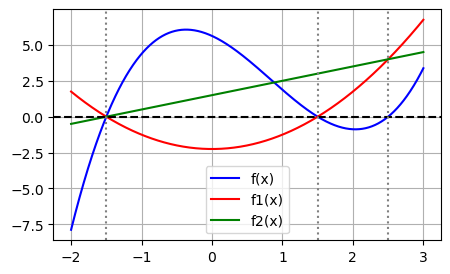

In [134]:
# Part 8

def f0(x):
    return f1(x)

def f_def1(x):
    return (x+1.5)*(x-1.5)

def f_def2(x):
    return x+1.5

xs = np.linspace(-2, 3, 1000)
plt.figure(figsize=(5,3))

plt.plot(xs, [f0(x) for x in xs], color='blue', label='f(x)')
plt.plot(xs, [f_def1(x) for x in xs], color='red', label='f1(x)')
plt.plot(xs, [f_def2(x) for x in xs], color='green', label='f2(x)')

plt.axhline(0, color='k', ls='dashed')
plt.axvline(-1.5, color='gray', ls='dotted')
plt.axvline(1.5, color='gray', ls='dotted')
plt.axvline(2.5, color='gray', ls='dotted')

plt.legend(loc='best')
plt.grid()
plt.show()

##### Part 9

Suppose the polynomial can be written as the product (x-x1)(x-x2)...(x-xN)
Then Newton's modified approach for the root x1 is (x-x1)(x-x2)...(x-xN)/(x-x1)

The factor (x-x1) has been removed, so x1 is no longer a root of the deflated polynomial. Repeating this process, removes one root at each successful step. After N successful steps, all N roots have been found.
The derivative at every stage is simply the derivative of the current deflated polynomial, which is what the code calculates using np.polyder.

# Question 4 [2+6+6+6+6+8+8+12+8+8+6 marks]

We will deal with data and try to create an analytic model that can represent the data. `epidemic_rise_data.csv` contains the daily new infection numbers during a viral epidemic in a state. An epidemic initially spreads rapidly. After some time, as antibodies develop, new infections decrease. Consider the number of new infections is given by some function $N(t)$ and $t$ is the time given in days. Let's also assume that $N(t) = Ae^{-B(t-C)^2}$, where ${\bf p}\equiv[A, B, C]$ are parameters we want to find. We want to understand the spread and wane of the epidemic. 

1. Use an appropriate module from pandas to load the data. 
2. Plot the data to visualise. Based on the plot, try to guess the values of $A$ and $C$. Give explanation. 
3. Using a few guesses of $B$ and your guessses for $A$ and $C$, plot the model function with the data. In this process you try to get a reasonably good guess of ${\bf p}$.
4. Write a function that can evaluate $f'(x)$ given $f(x)$ using first central difference, appropriate $h$, and any other arguments you need.  
5. Write a function (and any other helper functions you want) that calculates the sum of squared residuals $S(A, B, C) = \sum_{i=0}^n \left( Ae^{-B(t_i-C)^2} - N_i \right)^2$, where $i$ denotes the index of the data. You may want to use `numpy.sum` for this.

We want to minimise $S$ with respect to the parameter vector ${\bf p}$. This can be done by solving the coupled equations $S'_A\equiv\dfrac{\partial S}{\partial A} = 0$, $S'_B\equiv\dfrac{\partial S}{\partial B} = 0$, $S'_C\equiv\dfrac{\partial S}{\partial C} = 0$. In vector notation, we can write 
$${\bf G}\equiv\left[S'_A, S'_B, S'_C\right]\equiv\left[\dfrac{\partial S}{\partial A}, \dfrac{\partial S}{\partial B}, \dfrac{\partial S}{\partial C}\right]=0.$$ Of course this is not easy to do analytically. we will try to find a numerical solution. 

6. Write a function that returns ${\bf G}$ as a `numpy array` using the central difference module you have written above. Use a small enough $h\lesssim 10^{-5}$. 

Note that the roots of the matrix equation ${\bf G}=0$ will give us the optimam values of our unknown parameters ${\bf p}$. We will use a generalised form of Newton's method to find the roots. As discussed in class, we know that the iterative equation for Newton's method in one dimension is- 
$$ x^{k} = x^{(k-1)} - \dfrac{f\left( x^{(k-1)} \right)}{f' \left( x^{(k-1)} \right)}.$$ 
Of course, this can also be written as- 
$$f'\left( x^{(k-1)} \right) \left(x^{(k)} - x^{(k-1)}\right) = -f \left( x^{(k-1)} \right).$$
It will be clear why it is beneficial to write it in the latter form when we investigate the generalised version of the iterative equation. 

For the problem at hand, we want to solve ${\bf G}(A,B,C)=0$. We can write Newton's iterative equation in vector form as 
$${\bf p}^{(k)} = {\bf p}^{(k-1)} - {\bf J}^{-1}{\bf G} \left( {\bf{p}}^{(k-1)} \right),$$ 
where ${\bf J}$ is the Jacobian matrix where the elements are given by $J_{ij} = \dfrac{\partial G_i}{\partial p_j}$, where $i$, $j$ denote the vector indices. For our problem ${\bf J}$ is a $3\times3$ matrix. Since it is cumbersome to explicitly invert a matrix (and can be dangerous), we will instead use the modified form of the equation-
$${\bf J}\left({\bf p}^{(k)}-{\bf p}^{(k-1)}\right) = - {\bf G}\left( {\bf{p}}^{(k-1)} \right)$$
$$\implies {\bf J}\left({\bf \Delta p}\right) = - {\bf G}\left( {\bf{p}}^{(k-1)} \right),$$
where ${\bf p}^{(k)}={\bf p}^{(k-1)} + {\bf \Delta p}$. It should be obvious that in this form, the iterator becomes a simple linear algebraic equation that you need to solve and not a situation where you need to explicitly invert a matrix repeatedly. 

7. Write a function that calculates the Jacobian matrix ${\bf J}$ and returns it as a `numpy.array`. You will need to call the functions you have written before in this problem in an appropriate manner. Hence, plan the arguments accordingly. Use an appropriately small $h\lesssim 10^{-5}$. 
8. Write a function that solves the iterative equation repeatedly until tolerance is reached. Use tolerance $10^{-5}$. **This function should also print out the iteration number, sum of squared residuals, parameter values at that iteration, and the norm of ${\bf G}$.** You can use the convergence equation as- **norm of ${\bf G}$ $<\rm{tolerance}$**. You may want to use `numpy.linalg.norm` for calculation of norm. It is important that you use a `try-except` control flow to safeguard your code from situations where ${\bf J}$ is singualr or close to singular. You may want to use `numpy.linalg.solve` for the Newtonian update step. You may want to use `numpy.linalg.LinAlgError` as an except clause to safeguard yourself from singularities. It is very important to start from a reasonably good initial guess of ${\bf p}$. This is multidimensional non-linear optimisation. You do not want your iterator to get stuck at some local minima somewhere far from the solution. Use the good guess you found by visualising the data in part 3. 
9. Run the Newton solver to find the solution and report it. 
10. Generate a final plot showing the data, your initial guess, and the best-fit model. The best-fit values should also be written on the plot. 
11. Try some other initial guesses away from the optimal ${\bf p}$. Does it always converge? If you found that it does not, this is correct. This is an unavoidable problem of nonlinear optimisation. 

**Note:** Congratulations. You have learned how to generalise the one-dimensional Newton's solver. You have also learned multidimensional optimisation.

In [135]:
# Part 1

#We use Pandas to extract the data from the file epidemic_rise_data.csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("epidemic_rise_data.csv")

print(df.head())
print(df.columns)

   Time_t_days(t)  daily_new_infections(N)
0             1.0                    185.0
1             2.0                    980.0
2             3.0                   3100.0
3             4.0                   4720.0
Index(['Time_t_days(t)', 'daily_new_infections(N)'], dtype='object')


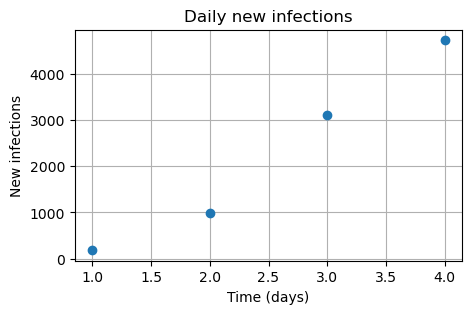

In [136]:
#Part 2

t = df.iloc[:, 0].to_numpy(dtype=float)
N = df.iloc[:, 1].to_numpy(dtype=float)

plt.figure(figsize=(5,3))
plt.plot(t, N, 'o')
plt.xlabel("Time (days)")
plt.ylabel("New infections")
plt.title("Daily new infections")
plt.grid()
plt.show()

Initial guess for A: 4720.0
Initial guess for C: 4.0
Try these B values: [0.011111111111111112, 0.1111111111111111, 0.5555555555555556]


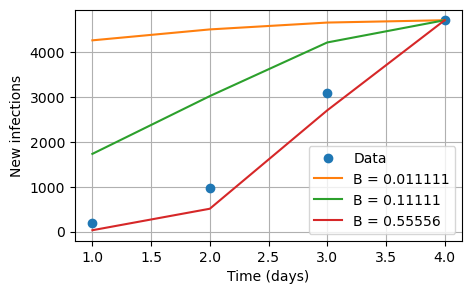

In [137]:
#Part 3

#Since the exponential reaches its maximum when t=C, 
#   A ~ max(N), C = T(at maximum)

A0 = np.max(N)
C0 = t[np.argmax(N)]

T = np.max(t) - np.min(t)
B_guesses = [0.1/T**2, 1/T**2, 5/T**2]

plt.figure(figsize=(5,3))
print("Initial guess for A:", A0)
print("Initial guess for C:", C0)
print("Try these B values:", B_guesses)

plt.plot(t, N, 'o', label="Data")

for B0 in B_guesses:
    N_guess = A0*np.exp(-B0*(t-C0)**2)
    plt.plot(t, N_guess, label=f"B = {B0:.5g}")

plt.xlabel("Time (days)")
plt.ylabel("New infections")
plt.legend()
plt.grid()
plt.show()

In [138]:
# We choose B0 whose curve fits the data reasonably well. The initial parameter vector is then the following:-
p0 = np.array([A0, B_guesses[1], C0])

In [139]:
#Part 4 and Part 5

# We define the central difference
def central_diff(f, x, h=1e-5):
    return (f(x+h)-f(x-h))/(2*h)

# We define the sum of residues as mentioned in the question
def S(p, t, N):
    A, B, C = p
    N_model = A*np.exp(-B*(t-C)**2)
    return np.sum((N_model-N)**2)

In [140]:
# Part 5 and Part 6

def G(p, t, N, h=1e-5):
    g = []

    for j in range(3):
        def sj(x):
            pnew = p.copy()
            pnew[j] = x
            return S(pnew, t, N)

        g.append(central_diff(sj, p[j], h))
    return np.array(g)

def Jacobian(p, t, N, h=1e-5):
    J = np.zeros((3, 3))

    for j in range(3):
        def gj(x):
            pnew = p.copy()
            pnew[j] = x
            return G(pnew, t, N)

        for i in range(3):
            J[i, j] = central_diff(
                lambda x: gj(x)[i], p[j], h
            )
    return J

In [141]:
# Part 7 and Part 8

#Now we solve for J delta P = -G and pnew = p + delta p using the formulae mentioned clearly in the question.

def newton_system(p, t, N, kmax=100, tol=1e-5):
    p = p.copy()

    for k in range(kmax):
        g = G(p, t, N)
        normG = np.linalg.norm(g)

        print("Iteration:", k)
        print("S =", S(p, t, N))
        print("Parameters [A, B, C] =", p)
        print("Norm of G =", normG)
        print()

        if normG < tol:
            print("Converged!")
            return p

        J = Jacobian(p, t, N)

        try:
            dp = np.linalg.solve(J, -g)
        except np.linalg.LinAlgError:
            print("Jacobian is singular. Try another initial guess.")
            return None

        p = p + dp

        if not np.all(np.isfinite(p)):
            print("Iteration diverged. Try another initial guess.")
            return None

    print("Maximum iterations reached. No convergence.")
    return None

In [109]:
# Part 9

p0 = np.array([4720, 5/9, 4.0])

pbest = newton_system(p0, t, N)

if pbest is not None:
    print("Best-fit parameters [A, B, C]:", pbest)
    print("Minimum sum of squared residuals:", S(pbest, t, N))

Iteration: 0
S = 396537.23806193
Parameters [A, B, C] = [4.72000000e+03 5.55555556e-01 4.00000000e+00]
Norm of G = 5383140.999682476

Iteration: 1
S = 143277.9690942904
Parameters [A, B, C] = [4.70806152e+03 5.89589473e-01 3.77415493e+00]
Norm of G = 953517.5204159274

Iteration: 2
S = 134141.8651318677
Parameters [A, B, C] = [4.53986222e+03 3.61297748e-01 3.92523858e+00]
Norm of G = 3725155.7240326963

Iteration: 3
S = 3153.184755771147
Parameters [A, B, C] = [4.69348624e+03 3.79416906e-01 4.03894334e+00]
Norm of G = 92185.8013423251

Iteration: 4
S = 1114.025782084086
Parameters [A, B, C] = [4.72795750e+03 3.58971337e-01 4.08330467e+00]
Norm of G = 75119.61335758741

Iteration: 5
S = 1040.0068144749482
Parameters [A, B, C] = [4.73453050e+03 3.57365725e-01 4.09029730e+00]
Norm of G = 418.0779895374686

Iteration: 6
S = 1039.8760355706622
Parameters [A, B, C] = [4.73486337e+03 3.57188226e-01 4.09075232e+00]
Norm of G = 5.881177627037149

Iteration: 7
S = 1039.8760350071434
Parameters [

As we can see we got a nice good fit for the choosen initial guess.


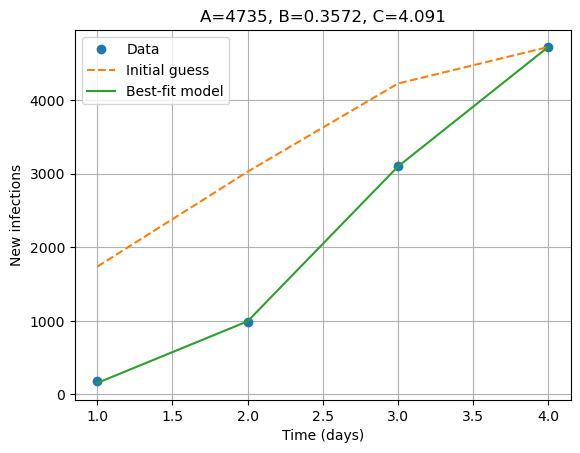

In [142]:
# Part 10

print("As we can see we got a nice good fit for the choosen initial guess.")
plt.plot(t, N, 'o', label="Data")

N_initial = p0[0]*np.exp(-p0[1]*(t-p0[2])**2)
plt.plot(t, N_initial, '--', label="Initial guess")

if pbest is not None:
    A, B, C = pbest
    N_best = A*np.exp(-B*(t-C)**2)

    plt.plot(t, N_best, label="Best-fit model")
    plt.title(f"A={A:.4g}, B={B:.4g}, C={C:.4g}")

plt.xlabel("Time (days)")
plt.ylabel("New infections")
plt.legend()
plt.grid()
plt.show()

In [143]:
# Part 11

# Now we run it for a variety of runs
for ptest in [
    np.array([A0, B_guesses[0], C0]),
    np.array([A0, B_guesses[2], C0]),
    np.array([0.8*A0, B_guesses[1], C0+5])
]:
    print("Initial guess:", ptest)
    result = newton_system(ptest, t, N)

    if result is not None:
        print("Final parameters:", result)
    print("-"*40)

Initial guess: [4.72000000e+03 1.11111111e-02 4.00000000e+00]
Iteration: 0
S = 31647090.381927274
Parameters [A, B, C] = [4.72000000e+03 1.11111111e-02 4.00000000e+00]
Norm of G = 456425735.93733245

Iteration: 1
S = 141570900.17160937
Parameters [A, B, C] = [ 7.73444771e+03 -4.47306976e-03  1.24493009e-01]
Norm of G = 2006653485.210648

Iteration: 2
S = 57391974.73087459
Parameters [A, B, C] = [4.10974087e+04 1.21670927e-02 1.52053861e+01]
Norm of G = 28153639031.059116

Iteration: 3
S = 10528970.36900099
Parameters [A, B, C] = [3.90605678e+04 1.30198939e-02 1.60297269e+01]
Norm of G = 7966508024.466537

Iteration: 4
S = 3014602.3543908074
Parameters [A, B, C] = [3.90749149e+04 1.37874529e-02 1.64793539e+01]
Norm of G = 1828910195.2739844

Iteration: 5
S = 2254510.648198232
Parameters [A, B, C] = [3.91099603e+04 1.49933342e-02 1.62029455e+01]
Norm of G = 400636115.84752035

Iteration: 6
S = 2476046.6114875153
Parameters [A, B, C] = [3.90917291e+04 1.95989748e-02 1.42384689e+01]
Norm o

Iteration: 90
S = 506546.2790670827
Parameters [A, B, C] = [3.86964286e+04 4.44148190e-02 1.08182833e+01]
Norm of G = 17.720635589518878

Iteration: 91
S = 506543.42917591234
Parameters [A, B, C] = [3.86947191e+04 4.44159466e-02 1.08181216e+01]
Norm of G = 2.8774167973973523

Iteration: 92
S = 506546.046772887
Parameters [A, B, C] = [3.86962892e+04 4.44153209e-02 1.08182362e+01]
Norm of G = 2.506720670511584

Iteration: 93
S = 506543.85158287187
Parameters [A, B, C] = [3.86949724e+04 4.44158881e-02 1.08181366e+01]
Norm of G = 3.2053715646813514

Iteration: 94
S = 506545.7065567824
Parameters [A, B, C] = [3.86960852e+04 4.44153937e-02 1.08182220e+01]
Norm of G = 2.415885200177181

Iteration: 95
S = 506543.5115621998
Parameters [A, B, C] = [3.86947685e+04 4.44159190e-02 1.08181259e+01]
Norm of G = 1.916215774421634

Iteration: 96
S = 506545.20242915454
Parameters [A, B, C] = [3.86957827e+04 4.44155313e-02 1.08181985e+01]
Norm of G = 1.9383735671994218

Iteration: 97
S = 506540.0408630237

As we can observe the outcomes of our runs, it is clear that many of the test cases diverge. This is evident when we eyeball the norm of G. As mentioned in the question, this should be the case because non-linear optimisation problems are inherently face difficulties from divergences.